In [0]:
from google.colab import files
import io
import os

import csv

import statsmodels.api as sm
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

In [0]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)
root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'

Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&response_type=code&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly

Enter your authorization code:
··········
Mounted at /content/drive/


# I. Import Data

In [0]:
#root_path = 'drive/My Drive/ECI Research/Spring 2020/Data'

# Read input
#uploaded = files.upload()
df = pd.read_csv(root_path+'2013-2018 cleaned/2015clean.csv')
df1_cl= pd.read_csv(root_path+'2013-2018 cleaned/2015clean.csv', index_col=0)
#uploaded = files.upload()
df2 = pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv')
df2_cl= pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv', index_col=0)

In [0]:
df = pd.read_csv(root_path+'2013-2018 cleaned/2013clean.csv')
raw_matrix = df.to_numpy()
matrix = [list(df.columns)]

for row in raw_matrix:
  if np.min(row[1::]) > 0:
    matrix.append(list(row))

country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix2)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)


eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#print(sorted_eci_dict)
for item in sorted_eci_dict:
  print(item)

raw_matrix2 = df2.to_numpy()
matrix2 = [list(df2.columns)]

for row in raw_matrix2:
  if np.min(row[1::]) > 0:
    matrix2.append(list(row))

In [0]:
list(df.columns)

['Name',
 'Animals and By-products',
 'Vegetables, Fruits and Plants',
 'Food and Preparations',
 'Energy Drilling and Mining',
 'Chemicals',
 'Chemical Manufacturing',
 'Raw Manufacturing',
 'Wood Products',
 'Clothing and Accessories',
 'Textile',
 'Metals',
 'Machinery and Construction',
 'Transportation',
 'Weapons',
 'Daily Instruments',
 'Precious Stones',
 'High-complexity Products',
 'Services and Utilities ']

# ECI & PCI

MCP

In [0]:
#compute mcp

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])
    
  country_sum = []
  for i in range(1,len(matrix)):
    country_sum.append(np.sum(matrix[i][1::]))
    
  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcp = []
    
  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [0]:
#compute mcc
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [0]:
# compute mpp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [0]:
#compute ECI
def compute_eci(mcc):
  mcc = np.array(mcc)
    
  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [0]:
#compute PCI
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

In [0]:
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix2)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)


eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_18 = {}
for i in range(len(country_list_18)):
  eci_dict_18[country_list_18[i]]=eci_18[i]
sorted_eci_dict_18 = sorted(eci_dict_18.items(), key=operator.itemgetter(1))

#print(sorted_eci_dict)
for item in sorted_eci_dict:
  print(item)

('Angola', -1.363857097347638)
('Azerbaijan', -1.2212320488458155)
('Mongolia', -1.1809048042868842)
('Ethiopia', -1.1179741975429245)
('Burkina Faso', -1.0858214386190013)
('Ecuador', -1.0782709238731965)
('Rwanda', -1.0782709238731965)
('Paraguay', -1.0164552347089655)
('French Polynesia', -1.0068743805045857)
('Nicaragua', -0.9235892155767497)
('United Republic of Tanzania', -0.9089897010433854)
('Zimbabwe', -0.8777988727412862)
('Lesotho', -0.8703010543963785)
('Plurinational State of Bolivia', -0.8567579293636401)
('Namibia', -0.8492642192115948)
('Armenia', -0.845053807466767)
("C̫te d'Ivoire", -0.802593386493637)
('Myanmar', -0.8017495374732023)
('Honduras', -0.780785779898434)
('United Arab Emirates', -0.7732781216529272)
('Mauritius', -0.7518187275795781)
('Seychelles', -0.7392529051833783)
('Belize', -0.7392529051833783)
('Kyrgyzstan', -0.73163582562343)
('Argentina', -0.7277357777898023)
('South Africa', -0.7243838226910114)
('Botswana', -0.7235218841677468)
('Bangladesh', -

# Proximity, Distance, and ADI

Proximity

In [0]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [0]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

ADI

In [0]:
def compute_adi(df2,country_list,distance):
  raw_matrix = df2.to_numpy()
  matrix = [list(df2.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2 

In [0]:
proximity = compute_proximity(mcp,product_sum)
proximity_18 = compute_proximity(mcp_18,product_sum_18)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [0]:
print(adi)

{'Bulgaria': array([ 0.01186349, -0.12851017, -0.10579707, -0.0686481 , -0.08504441,
       -0.01891658, -0.04682256, -0.12488633, -0.09560396, -0.13382552,
       -0.06264721,  0.03474898,  0.0125054 , -0.09973054, -0.03864348,
       -0.06095479,  0.02915961, -0.02425068]), 'Myanmar': array([-0.05338171, -0.03851478, -0.06020596, -0.06690365,  0.001756  ,
       -0.03474489, -0.07529045, -0.05064724, -0.07917871, -0.05895414,
        0.01296186, -0.03913165,  0.03468777, -0.04944   , -0.04220498,
       -0.03762651, -0.01093485, -0.01035761]), 'Burundi': array([0.05085601, 0.07589225, 0.07192576, 0.10701962, 0.07128366,
       0.07782525, 0.03925868, 0.0839017 , 0.08316362, 0.07191107,
       0.10099421, 0.14992761, 0.18614848, 0.03782538, 0.14405559,
       0.04636986, 0.17721649, 0.03515685]), 'Belarus': array([-0.13392284, -0.14218962,  0.01686466, -0.12599318, -0.07980626,
       -0.11275015, -0.11893252, -0.11133927, -0.13793675, -0.09843239,
       -0.12482721, -0.06167543, -0.

# Sequential Strategy

Opportunity Gain

In [0]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [0]:
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)
    
  marginal = np.array(marginal)
  return marginal

In [0]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

In [0]:
# For computation of sequential strategies, refer to sequential strategy.py

In [0]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [0]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [0]:
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])
    
    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))
    
    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)
    
    #print(product_list)
    #print(country_list)

    mcp = []
    
    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)
    
    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))
    
    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)
    
    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)
    
    #compute PCI
    mpp = np.array(mpp)
    
    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)
    
    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])
    
    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))
    
    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)
    
    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)
    
    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)
        
    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)
    
    
    
    
    
    #computing sequential strategy
    strategy = []
    
    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    #print("Before Iteration: ")
    #for i in range(0,len(marginal[country_index])):
    #    print(product_list[i], ": ", marginal[country_index][i])
    #print(" ")
    
    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)
    
    ite_round = 0
    prev_industry = []
    
    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1
        
        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)
        
        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export
    
        #print("increase ", industry, " in ", country, " by ", export_increase, " USD")
    
        raw_matrix[country_index+1][industry_index+1] = required_export*1.3
        
        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))
    
        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)
    
        mcp = []
     
        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)
    
        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))
    
        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)
    
        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)
    
        #compute PCI
        mpp = np.array(mpp)
    
        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)
    
        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])
    
        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))
    
        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)
    
        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)
    
        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)
        
        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)
        
        #print("Iteration ", ite_round, ": ")
        #for i in range(0,len(marginal[country_index])):
        #    print(product_list[i], ": ", marginal[country_index][i])
        #print(" ")
        
        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)
    
    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')
    
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    print(f'{country} completed')
    
def main():
    countries = ['Brazil', 'USA', 'Mexico', 'Argentina', 'Colombia',       
               'France', 'Germany', 'Spain', 'Greece', 'Portugal', 'Italy', 'Poland',
               'Turkey', 'Saudi Arabia', 'United Arab Emirates',
               'Morocco', 'South Africa', 'Egypt', 'Nigeria', 'Rwanda', 'Tunisia', 'Ethiopia', 'Algeria',
               'China', 'Republic of Korea', 'Japan', 'Malaysia', 'Thailand', 'Singapore', 'Indonesia']
               
    for country in countries:
        sdv_and_sids(country, root_path+'2013-2018 cleaned/2013clean')

In [0]:
if __name__ == "__main__":
    main()   #Change the countries and year above to have different results

NameError: ignored

# SOI

In [0]:
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

In [0]:
def compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append([item])
                    reg = LinearRegression()
                    reg.fit(independent, dependent)
                    r_2 = reg.score(independent, dependent)
                    common.append(country_list[i])
                    # if country_list[i] == "China":
                    #      matrix = open(root_path+"soi analysis TEST ROHAN.csv",'w',newline='')
                    #      writer = csv.writer(matrix)
                    #      start = ["Product","OG","Export Increase"]
                    #      writer.writerow(start)
                    #      for i in range(0,len(independent)):
                    #          temp = [product_list[i],independent[i][0],dependent[i]]
                    #          writer.writerow(temp)
                    #      matrix.close()
                    soi[country_list[i]] =r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index adi.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
        temp = [common[i],soi[common[i]]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [0]:
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    common=np.intersect1d(country_list, country_list2)
    for i in range(0,len(common)):
        dependent = []
        independent = []
        for item in opportunity_gain[i]:
            independent.append([item])
        #print(opportunity_gain2[i])
        for item in opportunity_gain2[i]:
            dependent.append([item])
        reg = LinearRegression()
        reg.fit(independent, dependent)
        r_2 = reg.score(independent, dependent)
        soi[common[i]] =r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [0]:
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    common=np.intersect1d(country_list, country_list2)
    commonp=np.intersect1d(product_list, product_list2)
    for i in range(0,len(common)):
        dependent = []
        independent = []
        for item in opportunity_gain[i]:
            independent.append([item])
        #print(opportunity_gain2[i])
        for item in exp_change.loc[]:
            dependent.append([item])
        reg = LinearRegression()
        reg.fit(independent, dependent)
        r_2 = reg.score(independent, dependent)
        soi[common[i]] =r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [0]:
def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []

    for i in common:
        if i in gdp_raw.index.values:
            name.append(i)
            pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])
            dependent.append(pct_change)
            independent.append(soi[i])
    plt.scatter(independent,dependent)
    plt.title('SOI v GDP Growth')
    plt.xlabel('SOI')
    plt.ylabel('% Change in GDP')
    plt.show()
    data = np.array(independent)
    X = sm.add_constant(data)
    model = sm.OLS(dependent, X).fit()
    return model

SOI w/ ADI

categorization verified
{'Bulgaria': 0.15217597830961904, 'Myanmar': 0.007269406550821977, 'Burundi': 0.06935317146564757, 'Belarus': 0.056278122910347506, 'Canada': 0.25399824894368384, 'Chile': 0.0010547590147590435, 'China': 0.060653822941697966, 'Colombia': 0.11970301359644141, 'Costa Rica': 0.16806730356334887, 'Croatia': 0.062088424342153226, 'Cyprus': 0.13807285161494542, 'Andorra': 0.08592433504656372, 'Czechia': 0.2687759896384331, 'Denmark': 0.1855472318695227, 'Ecuador': 0.004015880612875056, 'El Salvador': 0.15065312752341056, 'Estonia': 0.5956370081591846, 'Angola': 0.004675762871497846, 'Fiji': 0.0033026966417296637, 'Finland': 0.007475548450839421, 'France, Monaco': 0.009774192260386005, 'Georgia': 0.10480623902201691, 'Gambia': 0.06611652278074387, 'State of Palestine': 0.17781178533099307, 'Germany': 0.4897304932739196, 'Antigua and Barbuda': 0.0005279267599962445, 'Greece': 0.021531102331416307, 'Azerbaijan': 0.2479641077855511, 'Argentina': 0.00022122934005641695, 'C

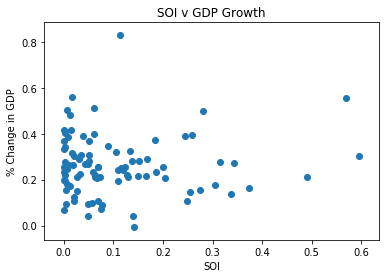

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.010
Method:                 Least Squares   F-statistic:                    0.1221
Date:                Wed, 26 Feb 2020   Prob (F-statistic):              0.728
Time:                        05:03:15   Log-Likelihood:                 56.692
No. Observations:                  91   AIC:                            -109.4
Df Residuals:                      89   BIC:                            -104.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2580      0.018     14.306      0.000       0.222       0.294
x1             0.0385      0.110      0.349      0.728      -0.181       0.258
==============================================================================
Omnibus:                       25.431   Durbin-Watson:                   1.694
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               48.892
Skew:                           1.067   Prob(JB):                     2.42e-11
Kurtosis:                       5.888   Cond. No.                         8.11
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [0]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
print(soi_adi)
gdp_raw=pd.read_csv(root_path+'GDP3.csv', index_col=0).fillna(0)
reg= compute_regress(soi_adi, gdp_raw, country_list, country_list2)
reg.summary()

SOI w/ Opportunity Gain

categorization verified
[('Andorra', 0.747226764890436), ('Angola', 0.6032119871467287), ('Antigua and Barbuda', 0.33586327060834853), ('Argentina', 0.7489448048741839), ('Armenia', 0.21264829523732456), ('Aruba', 0.6704602418801285), ('Australia', 0.005145083245922), ('Austria', 0.09210491760672512), ('Azerbaijan', 0.499161260411317), ('Bahrain', 0.030501645051642212), ('Barbados', 0.2546791979872668), ('Belarus', 0.44443375308757005), ('Belgium', 0.0009599126396429013), ('Belize', 0.3183630022490323), ('Bermuda', 0.010363011824603086), ('Bosnia Herzegovina', 0.008119765228239761), ('Botswana', 0.6720708718151307), ('Brazil', 0.021194394549076123), ('Brunei Darussalam', 0.38335689882105506), ('Bulgaria', 0.3114033190841379), ('Burkina Faso', 0.2752395500571433), ('Burundi', 0.39442453655999987), ('Canada', 0.710496279280769), ('Chile', 0.21196984599052893), ('China', 0.05053030559519123), ('China, Hong Kong Special Administrative Region', 0.07158954487690894), ('Colombia', 0.471285946

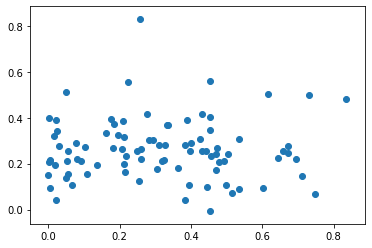

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.011
Method:                 Least Squares   F-statistic:                   0.02815
Date:                Wed, 26 Feb 2020   Prob (F-statistic):              0.867
Time:                        05:01:49   Log-Likelihood:                 54.437
No. Observations:                  89   AIC:                            -104.9
Df Residuals:                      87   BIC:                            -99.90
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2591      0.025     10.495      0.000       0.210       0.308
x1             0.0110      0.066      0.168      0.867      -0.119       0.141
==============================================================================
Omnibus:                       24.290   Durbin-Watson:                   1.687
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.211
Skew:                           1.047   Prob(JB):                     1.52e-10
Kurtosis:                       5.794   Cond. No.                         5.12
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [0]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_18, product_list_18, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_18)
reg_opp.summary()

In [0]:
exp_change= (df1_cl-df2_cl)/df1_cl

In [0]:
exp_change

,Animals and By-products,"Vegetables, Fruits and Plants",Food and Preparations,Energy Drilling and Mining,Chemicals,Chemical Manufacturing,Raw Manufacturing,Wood Products,Clothing and Accessories,Textile,Metals,Machinery and Construction,Transportation,Weapons,Daily Instruments,Precious Stones,High-complexity Products,Services and Utilities
Name,,,,,,,,,,,,,,,,,,
Afghanistan,-0.984798,-0.473111,-16.133012,0.589597,-inf,-8.287559,-2.028423,-734.736458,-inf,0.744809,-inf,-inf,-inf,-inf,-inf,-1.552583,-34.426629,-2.252709
"Africa CAMEU region, not elsewhere specified",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,0.414802,-0.212131,0.311317,0.655568,0.869414,-0.209068,0.657393,-0.095309,-0.220767,-2.729318,0.672533,0.880679,0.943725,1.000000,0.576365,0.705554,0.868288,-2.774316
Algeria,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,1.000000,1.000000,1.000000
American Samoa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Uzbekistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Yemen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
